Columns in file: Index(['Index', 'Actual', 'SARIMA', 'LR', 'RF', 'Unnamed: 5', 'Unnamed: 6',
       'Unnamed: 7', 'MAE', 'MAPE', 'RMSE', 'R2 score'],
      dtype='str')


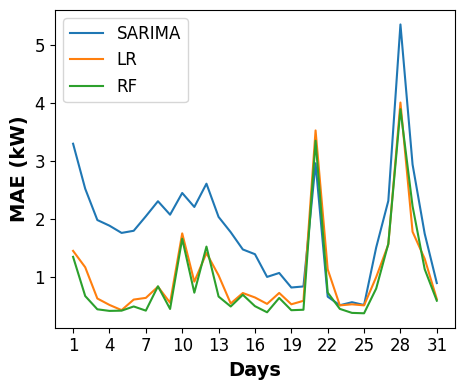

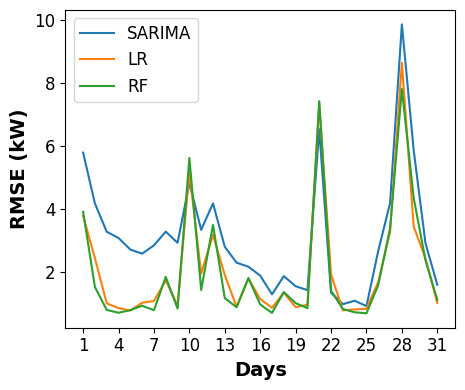

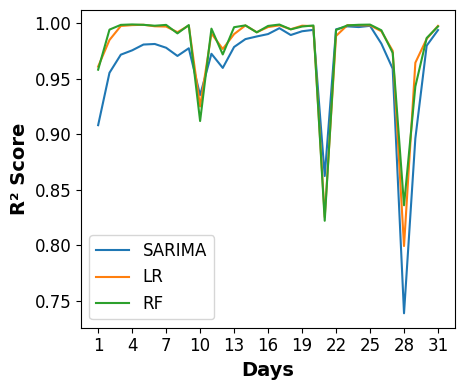

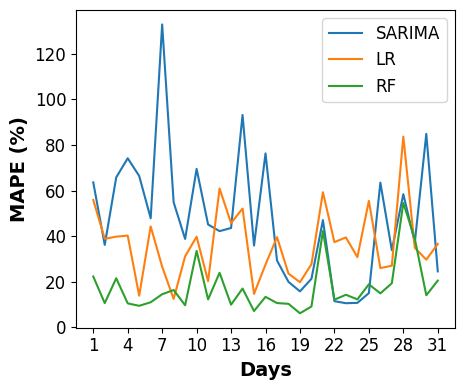

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# =========================================================
# LOAD FORECASTED DATA (ALL MODELS)
# =========================================================
df = pd.read_excel(r"C:\Users\Path Bhimani\OneDrive\Desktop\Forecasted table.xlsx")

print("Columns in file:", df.columns)

# =========================================================
# CHANGE THESE IF YOUR COLUMN NAMES ARE DIFFERENT
# =========================================================
y_actual = df['Actual'].values
y_sarima = df['SARIMA'].values
y_lr = df['LR'].values
y_rf = df['RF'].values

# =========================================================
# RESHAPE INTO DAYS (96 INTERVALS PER DAY)
# =========================================================
steps_per_day = 96
num_days = len(y_actual) // steps_per_day

y_actual = y_actual[:num_days * steps_per_day]
y_sarima = y_sarima[:num_days * steps_per_day]
y_lr = y_lr[:num_days * steps_per_day]
y_rf = y_rf[:num_days * steps_per_day]

actual_days = y_actual.reshape(num_days, steps_per_day)
sarima_days = y_sarima.reshape(num_days, steps_per_day)
lr_days = y_lr.reshape(num_days, steps_per_day)
rf_days = y_rf.reshape(num_days, steps_per_day)

# =========================================================
# COMPUTE DAILY ERROR METRICS
# =========================================================
daily_mae_sarima, daily_mae_lr, daily_mae_rf = [], [], []
daily_rmse_sarima, daily_rmse_lr, daily_rmse_rf = [], [], []
daily_r2_sarima, daily_r2_lr, daily_r2_rf = [], [], []
daily_mape_sarima, daily_mape_lr, daily_mape_rf = [], [], []

for i in range(num_days):
    actual = actual_days[i]

    pred_s = sarima_days[i]
    pred_l = lr_days[i]
    pred_r = rf_days[i]

    daily_mae_sarima.append(mean_absolute_error(actual, pred_s))
    daily_mae_lr.append(mean_absolute_error(actual, pred_l))
    daily_mae_rf.append(mean_absolute_error(actual, pred_r))

    daily_rmse_sarima.append(np.sqrt(mean_squared_error(actual, pred_s)))
    daily_rmse_lr.append(np.sqrt(mean_squared_error(actual, pred_l)))
    daily_rmse_rf.append(np.sqrt(mean_squared_error(actual, pred_r)))

    daily_r2_sarima.append(r2_score(actual, pred_s))
    daily_r2_lr.append(r2_score(actual, pred_l))
    daily_r2_rf.append(r2_score(actual, pred_r))

    mask = actual != 0
    daily_mape_sarima.append(np.mean(np.abs((actual[mask] - pred_s[mask]) / actual[mask])) * 100)
    daily_mape_lr.append(np.mean(np.abs((actual[mask] - pred_l[mask]) / actual[mask])) * 100)
    daily_mape_rf.append(np.mean(np.abs((actual[mask] - pred_r[mask]) / actual[mask])) * 100)

# =========================================================
# X-AXIS (DAYS)
# =========================================================
days = np.arange(1, num_days + 1)

# Show x-axis ticks in multiples of 2 days
xtick_days = np.arange(1, num_days + 1, 3)

# =========================================================
# 1. MAE GRAPH
# =========================================================
plt.figure(figsize=(4.75, 4))
plt.plot(days, daily_mae_sarima, label='SARIMA')
plt.plot(days, daily_mae_lr, label='LR')
plt.plot(days, daily_mae_rf, label='RF')

plt.xlabel('Days', fontweight='bold', fontsize=14)
plt.ylabel('MAE (kW)', fontweight='bold', fontsize=14)
plt.xticks(xtick_days, fontsize=12)
plt.yticks(fontsize=12)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

# =========================================================
# 2. RMSE GRAPH
# =========================================================
plt.figure(figsize=(4.75, 4))
plt.plot(days, daily_rmse_sarima, label='SARIMA')
plt.plot(days, daily_rmse_lr, label='LR')
plt.plot(days, daily_rmse_rf, label='RF')

plt.xlabel('Days', fontweight='bold', fontsize=14)
plt.ylabel('RMSE (kW)', fontweight='bold', fontsize=14)
plt.xticks(xtick_days, fontsize=12)
plt.yticks(fontsize=12)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

# =========================================================
# 3. R2 GRAPH
# =========================================================
plt.figure(figsize=(4.75, 4))
plt.plot(days, daily_r2_sarima, label='SARIMA')
plt.plot(days, daily_r2_lr, label='LR')
plt.plot(days, daily_r2_rf, label='RF')

plt.xlabel('Days', fontweight='bold', fontsize=14)
plt.ylabel('R² Score', fontweight='bold', fontsize=14)
plt.xticks(xtick_days, fontsize=12)
plt.yticks(fontsize=12)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

# =========================================================
# 4. MAPE GRAPH
# =========================================================
plt.figure(figsize=(4.75, 4))
plt.plot(days, daily_mape_sarima, label='SARIMA')
plt.plot(days, daily_mape_lr, label='LR')
plt.plot(days, daily_mape_rf, label='RF')

plt.xlabel('Days', fontweight='bold', fontsize=14)
plt.ylabel('MAPE (%)', fontweight='bold', fontsize=14)
plt.xticks(xtick_days, fontsize=12)
plt.yticks(fontsize=12)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()